# GNSS Radio Occultation Observations

Global Navigation Satellite System (GNSS) Radio Occultation (RO) samples the environment by observing changes to GNSS signals as the pass through the Earth's atmosphere. TAT-C models a GNSS-RO receiver as an instrument, `OccultationReceiver`, that a satellite carries, and the analysis function `collect_occultations` models when and where GNSS-RO observations can be sampled at the tangent point between a receiver and transmitter, i.e., the point along the line-of-sight with minimum geodetic altitude above the WGS 84 reference ellipsoid. This analysis *does not* consider atmospheric refraction, therefore represents only a coarse estimate of GNSS-RO observations suitable for early-stage mission analysis.

## Mathematical Basis

### Transmitter/Receiver Geometry

Assume the transmitter (tx) and receiver (rx) have positions $x_{tx}$ and $x_{rx}$ and velocities $v_{tx}$ and $v_{rx}$, respectively, in a geocentric inertial frame. The transmitter has position $x_{rx,tx}=x_{tx}-x_{rx}$ and velocity $v_{rx,tx}=v_{tx}-v_{rx}$ relative to the receiver.

<img src="../../_static/CollectRO/ro1.png" width=300>

The tangent point is the point on the line $x_{rx} + s\hat{d}$, with $\hat{d} = x_{rx,tx} / ||x_{rx,tx}||$, that has minimum geodetic altitude above the WGS 84 reference ellipsoid: the convention used to geolocate operationally processed GNSS-RO profiles. A first approximation is the point of minimum distance to the geocenter:

$x_{tp}^{(0)} = x_{rx} - \left(x_{rx} \cdot \hat{d}\right) \hat{d}$

The two coincide at the equator and poles but differ by up to about 20 km horizontally at middle latitudes (and by only meters in altitude). To find the ellipsoidal tangent point, positions are expressed in the Earth-fixed frame and the polar axis is scaled by $k = (a + h) / (b + h)$, where $a$ and $b$ are the WGS 84 equatorial and polar radii and $h$ is the current estimate of the tangent point's geodetic altitude. This turns the surface of constant geodetic altitude $h$ into very nearly a sphere, so the tangent point is the closest approach of the scaled line to the origin:

$s^* = -\frac{x'_{rx} \cdot \hat{d}'}{\hat{d}' \cdot \hat{d}'}, \qquad x_{tp} = x_{rx} + s^* \hat{d}$

where primes denote scaled Earth-fixed coordinates. Starting from $x_{tp}^{(0)}$, three refinements of $h$ converge to well below a millimeter.

The pitch angle of the transmitter as viewed by the receiver (above/below local horizon) is given by

$\theta_{rx,tx} = \text{atan2} \left( \tilde{x}_{tx,rx}^n \cdot \frac{x_{rx}}{||x_{rx}||}, \tilde{x}_{tx,rx}^n \cdot \frac{v_{rx}}{||v_{rx}||} \right)$

where

$\tilde{x}_{tx,rx}^n = x_{tx,rx} - (n_{rx} \cdot x_{tx,rx}) n_{rx}$ 

is the relative transmitter position in the plane normal to the receiver orbit, and 

$n_{rx} = \frac{ x_{rx} \times v_{rx}}{||x_{rx} \times v_{rx}||}$ 

is the unit normal to the receiver orbit plane.

<img src="../../_static/CollectRO/ro3.png" width=300>

The yaw angle of the transmitter as viewed by the receiver (left/right along local horizontal) is given by

$\Omega_{rx,tx} = \text{atan2} \left( \tilde{x}_{tx,rx}^t \cdot n_{rx}, \tilde{x}_{tx,rx}^t \cdot \frac{v_{rx}}{||v_{rx}||} \right)$

where

$\tilde{x}_{tx,rx}^t = x_{tx,rx} - (\frac{ x_{rx} }{||x_{rx} ||} \cdot x_{tx,rx}) \frac{ x_{rx} }{||x_{rx} ||}$ 

is the relative transmitter position in the plane tangent to the receiver orbit.

<img src="../../_static/CollectRO/ro4.png" width=300>

### RO Observation Criteria

There are three criteria for a valid RO observation.

First, the tangent point must be between the transmitter and receiver:

$\text{sgn} \left( (x_{tp} - x_{tx}) \cdot (x_{tp} - x_{rx}) \right) < 0$

<img src="../../_static/CollectRO/ro2.png" width=300>

Second, the absolute value yaw angle of the transmitter as viewed by the receiver must be within a maximum bound due to antenna gain patterns:

$\text{mod}\left( | \Omega_{rx,tx}|, 180 - \Omega_{max} \right) < \Omega_{max}$

Third, the elevation of the tangent point must be within a specified range:

$h_{min} < h < h_{max}$

where $h$ is the geodetic altitude of the tangent point $x_{tp}$ above the WGS 84 reference ellipsoid. Because atmospheric refraction is not modeled, $h$ is the altitude of the straight receiver-transmitter line, which passes well below the refracted signal path in the lower atmosphere.

## Analysis

First, we configure the receiver: an `OccultationReceiver` instrument, whose fields set valid GNSS-RO observation conditions between it and a transmitter:
 * `max_yaw` sets the maximum yaw angle (in degrees) between the receiver and transmitter within the receiver's orbit plane.
 * `range_elevation` sets the minimum and maximum allowable elevation (in meters) of the tangent point between receiver and transmitter, measured as geodetic altitude above the WGS 84 reference ellipsoid. While realistic GNSS-RO observations sample the atmosphere, a negative minimum value accounts for the lack of refraction considered in this analysis: the straight-line tangent point lies well below the refracted one in the lower atmosphere.
 * `sample_elevation` sets the elevation (in meters, geodetic altitude above the WGS 84 reference ellipsoid) of the tangent point to represent a GNSS-RO observation as a single point, rather than an arc through space. It is negative for the same reason.
 * `constellations` names the constellations of transmitters the receiver tracks, which the instrument catalog's navigation systems build (see `tatc.catalog.get_transmitters`); the analysis is given its transmitters, so these do not change it.

Other scenario parameters configure the temporal bounds of analysis (`start` and `end`) and set the time step (`time_step`) used to sample tangent point tracks within each valid observation period, once its bounds are found (via Skyfield's `find_discrete` search).

In [1]:
from datetime import datetime, timedelta, timezone
import numpy as np
from tatc.schemas import OccultationReceiver

# occultation receiver and its validity constraints
receiver = OccultationReceiver(
    name="TGRS",
    constellations=["gps", "glonass", "galileo", "beidou"],
    max_yaw=65,  # deg
    range_elevation=(-200e3, 60e3),  # m
    sample_elevation=-80e3,  # m
)

# scenario configuration
start = datetime(2023, 12, 9, tzinfo=timezone.utc)
time_step = timedelta(seconds=10)
duration = timedelta(hours=1)
end = start + duration
times = np.array([start + i * time_step for i in range(duration // time_step)])

Each analysis relies on the definition of a satellite that carries a GNSS receiver (e.g., COSMIC-2 FM5) and one or more GNSS transmitters (e.g., the GPS, GLONASS, Galileo, and BeiDou constellations). The code below imports two line elements (TLEs) for each satellite orbit (as of late 2023) and builds TAT-C `Satellite` objects. (Idealized orbits of the transmitters, without element sets, are built by `tatc.catalog.get_transmitters(receiver, start)`.)

In [2]:
from tatc.schemas import GeneralPerturbationsOrbit, Satellite

txs = []

for gnss_dat in ["elements/gps_tle.dat", "elements/glo_tle.dat", "elements/gal_tle.dat", "elements/bei_tle.dat"]:
    with open(gnss_dat, "r") as f:
        lines = f.read().splitlines()
        for i in range(0, len(lines), 3):
            txs.append(
                Satellite(
                    name=lines[i],
                    orbit=GeneralPerturbationsOrbit.from_tle(lines[i + 1 : i + 3]),
                )
            )

rx = Satellite(
    name="COSMIC-2 FM5",
    orbit=GeneralPerturbationsOrbit.from_tle(
        [
            "1 44358U 19036V   23354.40324524  .00015027  00000-0  91237-3 0  9994",
            "2 44358  24.0023   0.0734 0003537 251.0816 108.9304 15.08623759245240",
        ]
    ),
    instruments=[receiver],
)

TAT-C simulates GNSS-RO observations using the `collect_occultations` function, with the parameters of the receiver that each satellite carries (or `collect_ro_observations`, which takes them directly). The function propagates the position of the receiver and transmitters and, over the analysis period (`start` to `end`), uses Skyfield's `find_discrete` search to precisely identify periods that satisfy the three conditions required for a valid GNSS-RO observation: 1) the tangent point must be between the receiver and transmitter, 2) the receiver-transmitter yaw angle must be within `max_yaw` of the receiver's along-track direction (forward or aft), and 3) the tangent point elevation (geodetic altitude above the WGS 84 reference ellipsoid) must be within the `range_elevation` range.

All reported positions refer to the geodetic tangent point (longitude, latitude, and elevation above the WGS 84 reference ellipsoid). The outputs report each RO observation including the following fields:
 * `receiver`: the receiver satellite name
 * `instrument`: the receiver's name
 * `transmitter`: the transmitter satellite name
 * `is_rising`: true, if the tangent point rises through the sample elevation (a rising occultation); false indicates it descends (a setting occultation)
 * `geometry`: a multipoint geometry that describes the tangent point observation arc of points separated by (at most) `time_step`
 * `position`: a point geometry that describes the tangent point interpolated at the `sample_elevation` value
 * `rx_tx_pitch`: the transmitter pitch angle as viewed by the receiver
 * `rx_tx_yaw`: the transmitter yaw angle as viewed by the receiver
 * `tp_tx_azimuth`: the transmitter azimuth angle as viewed from the tangent point, in its local horizontal frame (i.e., degrees clockwise from North)
 * `start`: start of the RO observation arc
 * `end`: end of the RO observation arc
 * `time`: time of the observation interpolated at the `sample_elevation` value


In [3]:
from tatc.analysis import collect_occultations

ro_obs = collect_occultations(rx, txs, start, end, time_step=time_step)
display(ro_obs)

,receiver,instrument,transmitter,is_rising,geometry,position,rx_tx_pitch,rx_tx_yaw,tp_tx_azimuth,start,end,time
0,COSMIC-2 FM5,TGRS,BEIDOU-2 G7 (C03),False,MULTIPOINT Z ((-168.78429 -15.03756 -140025.93...,POINT Z (-168.78429398674876 -15.0375640992552...,-152.566529,-157.616782,273.572560,2023-12-09 00:00:00.000000+00:00,2023-12-09 00:00:19.836760+00:00,2023-12-09 00:00:00.000000+00:00
1,COSMIC-2 FM5,TGRS,GSAT0204 (PRN E22),True,MULTIPOINT Z ((-123.06999 -4.45876 57923.32257)),POINT Z (-123.06998977326161 -4.45875622590216...,-29.801735,46.330869,59.394126,2023-12-09 00:00:00.000000+00:00,2023-12-09 00:00:00.000000+00:00,2023-12-09 00:00:00.000000+00:00
2,COSMIC-2 FM5,TGRS,BEIDOU-3 G3 (C61),False,MULTIPOINT Z ((-168.50571 -15.59229 -124560.12...,POINT Z (-168.50571400325867 -15.5922943476104...,-152.660478,-156.371000,272.375069,2023-12-09 00:00:00.000000+00:00,2023-12-09 00:00:19.883965+00:00,2023-12-09 00:00:00.000000+00:00
3,COSMIC-2 FM5,TGRS,GPS BIIF-8 (PRN 03),True,MULTIPOINT Z ((-117.71587 -27.16628 -144224.09...,POINT Z (-117.30448603977223 -26.9246059662923...,-25.133449,-12.677234,112.653311,2023-12-09 00:00:00.000000+00:00,2023-12-09 00:01:18.724320+00:00,2023-12-09 00:00:25.816059+00:00
4,COSMIC-2 FM5,TGRS,COSMOS 2544 (759),False,MULTIPOINT Z ((-152.2312 5.83829 -11648.06603)...,POINT Z (-150.456308339518 6.168212586082146 -...,-147.257014,135.011799,334.192414,2023-12-09 00:00:00.000000+00:00,2023-12-09 00:01:49.818804+00:00,2023-12-09 00:00:43.831646+00:00
...,...,...,...,...,...,...,...,...,...,...,...,...
146,COSMIC-2 FM5,TGRS,BEIDOU-3 M4 (C22),True,MULTIPOINT Z ((95.25073 28.47106 -188980.23601...,POINT Z (95.70202898296276 27.858049979948856 ...,-24.888761,12.069412,87.006422,2023-12-09 00:58:40.446767+00:00,2023-12-09 01:00:00.000000+00:00,2023-12-09 00:59:23.115641+00:00
147,COSMIC-2 FM5,TGRS,BEIDOU-3 M7 (C27),False,"MULTIPOINT Z ((55.89148 42.5502 52750.64286), ...",POINT Z (56.53216994999153 42.79166738886379 4...,-136.432547,115.000000,325.221686,2023-12-09 00:59:28.725906+00:00,2023-12-09 00:59:38.695510+00:00,2023-12-09 00:59:38.695510+00:00
148,COSMIC-2 FM5,TGRS,GSAT0216 (PRN E25),False,"MULTIPOINT Z ((47.44227 31.77223 40796.57451),...",POINT Z (47.54128778069685 32.01378070460766 1...,-155.016884,152.255077,284.760405,2023-12-09 00:59:50.035183+00:00,2023-12-09 01:00:00.000000+00:00,2023-12-09 01:00:00.000000+00:00
149,COSMIC-2 FM5,TGRS,GPS BIIF-8 (PRN 03),False,"MULTIPOINT Z ((47.02776 22.78932 48345.14505),...",POINT Z (47.10808602979759 22.860539317446793 ...,-157.777087,176.485588,262.092703,2023-12-09 00:59:50.059435+00:00,2023-12-09 01:00:00.000000+00:00,2023-12-09 01:00:00.000000+00:00


The RO observations can be better visualized by combining with the receiver orbit track.

In [4]:
from tatc.analysis import collect_orbit_track

orbit_track = collect_orbit_track(rx, times)

The resulting plot shows the receiver orbit track and RO observations categorized as rising or setting.

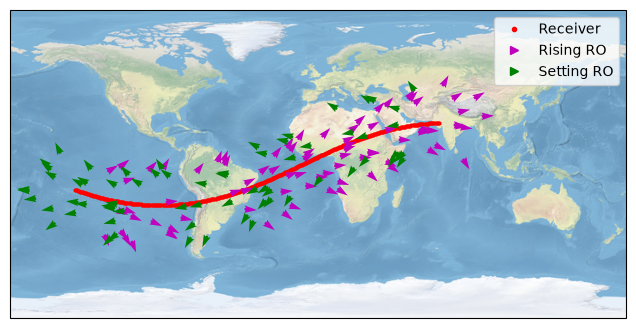

In [5]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import cartopy.crs as ccrs

fig, ax = plt.subplots(figsize=(10, 4), subplot_kw={"projection": ccrs.PlateCarree()})
orbit_track.plot(ax=ax, marker=".", color="r", lw=0, transform=ccrs.PlateCarree())
ax.quiver(
    ro_obs.apply(lambda r: r.position.x, axis=1),
    ro_obs.apply(lambda r: r.position.y, axis=1),
    ro_obs.apply(lambda r: np.sin(np.radians(r.tp_tx_azimuth)), axis=1),
    ro_obs.apply(lambda r: np.cos(np.radians(r.tp_tx_azimuth)), axis=1),
    color=ro_obs.apply(lambda r: "m" if r.is_rising else "g", axis=1),
    scale=50,
    scale_units="width",
    transform=ccrs.PlateCarree(),
)
ax.stock_img()
ax.set_global()
ax.legend(
    handles=[
        Line2D([0], [0], marker=".", color="r", lw=0, label="Receiver"),
        Line2D([0], [0], marker=">", color="m", lw=0, label="Rising RO"),
        Line2D([0], [0], marker=">", color="g", lw=0, label="Setting RO"),
    ]
)
plt.show()

An animation can show the dynamic collection of RO observations aggregated to individual (one-minute) frames over the first 30 minutes of the analysis period. The animation is an animated WebP image embedded in the notebook, which plays in a loop.

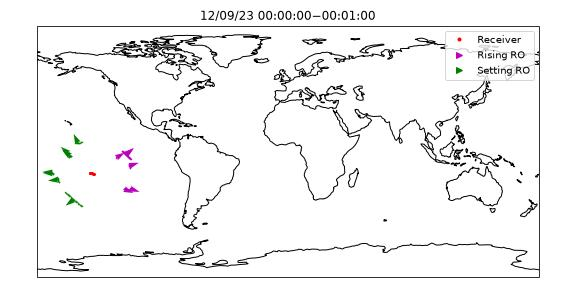

In [6]:
import base64
from datetime import timedelta
from io import BytesIO

from IPython.display import display
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from PIL import Image

fig, ax = plt.subplots(
    figsize=(8, 4), dpi=72, subplot_kw={"projection": ccrs.PlateCarree()}
)

frame_duration = timedelta(minutes=1)
animation_duration = timedelta(minutes=30)
num_frames = int(animation_duration / frame_duration)


def animate(frame):
    ax.clear()
    time = times[0] + frame * frame_duration
    orbit_track.loc[
        (orbit_track.time >= time) & (orbit_track.time < time + frame_duration)
    ].plot(ax=ax, marker=".", color="r", lw=0, transform=ccrs.PlateCarree())
    ro_obs_filtered = ro_obs.loc[
        (ro_obs.start >= time) & (ro_obs.start < time + frame_duration)
    ]
    if not ro_obs_filtered.empty:
        ro_obs_filtered.apply(
            lambda r: ax.plot(
                [point.x for point in r.geometry.geoms],
                [point.y for point in r.geometry.geoms],
                ".m" if r.is_rising else ".g",
                markersize=1,
                transform=ccrs.PlateCarree(),
            ),
            axis=1,
        )
        ax.quiver(
            ro_obs_filtered.apply(lambda r: r.position.x, axis=1),
            ro_obs_filtered.apply(lambda r: r.position.y, axis=1),
            ro_obs_filtered.apply(
                lambda r: np.sin(np.radians(r.tp_tx_azimuth)), axis=1
            ),
            ro_obs_filtered.apply(
                lambda r: np.cos(np.radians(r.tp_tx_azimuth)), axis=1
            ),
            color=ro_obs_filtered.apply(lambda r: "m" if r.is_rising else "g", axis=1),
            scale=50,
            scale_units="width",
            transform=ccrs.PlateCarree(),
        )
    ax.set_global()
    ax.coastlines()
    ax.set_aspect("equal")
    ax.legend(
        handles=[
            Line2D([0], [0], marker=".", color="r", lw=0, label="Receiver"),
            Line2D([0], [0], marker=">", color="m", lw=0, label="Rising RO"),
            Line2D([0], [0], marker=">", color="g", lw=0, label="Setting RO"),
        ]
    )
    ax.set_title(
        time.strftime("%x %X") + "$-$" + (time + frame_duration).strftime("%X")
    )
    fig.tight_layout()


def render_frame(frame):
    """The figure of a frame, as an image."""
    animate(frame)
    fig.canvas.draw()
    return Image.fromarray(np.asarray(fig.canvas.buffer_rgba())).convert("RGB")


def encode(image, **kwargs):
    """An image file, encoded as base64 text to embed in the notebook."""
    buffer = BytesIO()
    image.save(buffer, **kwargs)
    return base64.b64encode(buffer.getvalue()).decode()


frames = [render_frame(frame) for frame in range(num_frames)]
plt.close(fig)
webp = encode(
    frames[0],
    format="WEBP",
    save_all=True,
    append_images=frames[1:],
    duration=200,
    loop=0,
    quality=75,
    method=6,  # the slowest and smallest encoding
)
# An animated image in HTML, with the first frame as a still image for viewers without HTML.
display(
    {
        "text/html": f'<img src="data:image/webp;base64,{webp}" alt="Animation of the radio occultations collected in each minute">',
        "image/jpeg": encode(frames[0], format="JPEG", quality=75, optimize=True),
    },
    raw=True,
)